In [319]:
import itertools
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import altair as alt

from fashion.sources import HathiAll
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import silhouette_score
from scipy.sparse import csr_matrix

In [2]:
merged_no_dupe = pd.read_parquet("../data/final_for_analysis.parquet")

In [3]:
import pyarrow.parquet as pq

pq.read_schema("../data/final_for_analysis.parquet").names

['mention_id',
 'term',
 'sentence',
 'start_idx',
 'end_idx',
 'sentence_start_idx',
 'sentence_end_idx',
 'adjectives_fashion',
 'character_start_idx',
 'character_end_idx',
 'gender_local_pron',
 'all_genders',
 'gender_dep_pron',
 'adjectives_char',
 'gender_booknlp',
 'inferreddate',
 'decade',
 'decade_clean',
 'term_stem',
 'book_id',
 'character_id']

In [4]:
from dataclasses import dataclass
from pathlib import Path

import numpy as np
from tqdm import tqdm


@dataclass
class DocTermMatrix:
    mat: np.ndarray
    idx2word: list[str]
    word2idx: dict[str, int]
    idx2doc: list[str]
    doc2idx: dict[str, int]


def create_doc_term_mat(df, document_col, word_col, progress=False):
    idx2word = list(df[word_col].unique())
    word2idx = {v: k for k, v in enumerate(idx2word)}
    idx2doc = list(df[document_col].unique())
    doc2idx = {v: k for k, v in enumerate(idx2doc)}
    mat = np.zeros((len(doc2idx), len(word2idx)))
    for doc, word in tqdm(
        zip(df[document_col], df[word_col]), total=len(df), disable=not progress
    ):
        mat[doc2idx[doc]][word2idx[word]] += 1

    return DocTermMatrix(mat, idx2word, word2idx, idx2doc, doc2idx)


def logodds(matrix, group1, group2=None, min_occurrences=0, zscore=True):
    """
    Compute log odds for one against rest for K documents with N total unique words.

    The prior is computed over all of the words

    Filter out words with less than min_occurrences co-occurrences.
    """
    if not (isinstance(group1, set) or isinstance(group1, list)):
        group1 = set([group1])
    if not (isinstance(group2, set) or isinstance(group2, list)):
        group2 = set([group2])

    mat = matrix.mat.copy()
    mat[mat < min_occurrences] = 0

    _check_group1 = lambda x: x in group1  # noqa
    _check_group2 = (  # noqa
        lambda x: (x in group2) if group2 is not None else (not _check_group1(x))
    )

    def _log_odds_delta(mat, group1_idx, group2_idx, zscore):
        n_prior = mat.sum()
        g_1 = mat[group1_idx].sum(axis=0)
        g_2 = mat[group2_idx].sum(axis=0)
        n_1 = g_1.sum()
        n_2 = g_2.sum()

        prior = mat.sum(axis=0)

        l1 = (g_1 + prior) / ((n_1 + n_prior) - (g_1 + prior))
        l2 = (g_2 + prior) / ((n_2 + n_prior) - (g_2 + prior))
        delta = np.log(l1) - np.log(l2)
        if zscore:
            sigma = np.sqrt(1 / (g_1 + prior) + 1 / (g_2 + prior))
            delta = delta / sigma

        return delta

    group1_idx = [idx for idx, doc in enumerate(matrix.idx2doc) if _check_group1(doc)]
    group2_idx = [idx for idx, doc in enumerate(matrix.idx2doc) if _check_group2(doc)]

    return _log_odds_delta(mat, group1_idx, group2_idx, zscore=zscore)


def write_log_odds(
    matrix: DocTermMatrix,
    output_file: Path,
    group2=None,
    zscore=True,
    threshold=0,
    progress=True,
):
    with open(output_file, "w") as f:
        for c in tqdm(matrix.doc2idx, disable=not progress):
            lor = logodds(matrix, group1=c, group2=group2, zscore=zscore)
            for i in np.argsort(-lor):
                if np.abs(lor[i]) >= threshold:
                    f.write(
                        str(c)
                        + "\t"
                        + str(matrix.idx2word[i])
                        + "\t"
                        + str(lor[i])
                        + "\n"
                    )


def show_log_odds(df, document_col, word_col, group2=None, zscore=True, threshold=2):
    matrix = create_doc_term_mat(df, document_col, word_col)

    for c in matrix.doc2idx:
        lor = logodds(matrix, group1=c, group2=group2, zscore=zscore)
        print(c)
        for i in np.argsort(-np.abs(lor))[:10]:
            if np.abs(lor[i]) >= threshold:
                print("\t" + str(matrix.idx2word[i]) + "\t\t" + str(lor[i]))

In [17]:
merged_no_dupe["unique_char_id"] = merged_no_dupe.index.get_level_values(0) + "-" + merged_no_dupe.index.get_level_values(1).astype(str)

In [22]:
def create_mat():
    unique_mentions = merged_no_dupe#.groupby(by=["term"]).agg({"adjectives_char": "first", "decade": "first", "term": "first"})
    unique_mentions["term"] = unique_mentions.term.str.lower()
    unique_mentions = unique_mentions.explode("adjectives_char").dropna()
    unique_mentions["adjectives_char"] = unique_mentions.adjectives_char.str.lower()
    # only keep terms that occur at least 10 times and adjectives that occur at least 10 times
    
    n = 10
    unique_terms = unique_mentions.term.value_counts()
    unique_adjectives = unique_mentions.adjectives_char.value_counts()
    unique_mentions = unique_mentions[
        unique_mentions.term.isin(unique_terms[unique_terms >= n].index)
        & unique_mentions.adjectives_char.isin(
            unique_adjectives[unique_adjectives >= n].index
        )
    ]
    matrix = create_doc_term_mat(unique_mentions, "term", "adjectives_char")
    return matrix

matrix = create_mat()

In [58]:
merged_no_dupe.head()

mention_id      term  \
book_id             character_id                         
chi.086202240.clean 0               17370773    shorts   
                    218             17370789  covering   
                    218             17370790   topcoat   
                    0               17370796     shirt   
                    0               17370798     shirt   

                                                                           sentence  \
book_id             character_id                                                      
chi.086202240.clean 0             How long I remained in shorts I cannot novembe...   
                    218           Instantly I knew \nthat in order to assuage hi...   
                    218           Instantly I knew \nthat in order to assuage hi...   
                    0             Knowing in my own mind that \nmy shirt which I...   
                    0             Knowing in my own mind that \nmy shirt which I...   

                                  start_idx  end_idx  sentence_start_idx  \
book_id             character_id                                           
chi.086202240.clean 0                    23       29                4200   
                    218                 318      326               20869   
                    218                 334      341               20869   
                    0                    32       37               29540   
                    0                   277      282               29540   

                                  sentence_end_idx adjectives_fashion  \
book_id             character_id                                        
chi.086202240.clean 0                         4409                 []   
                    218                      21292             [thin]   
                    218                      21292                 []   
                    0                        29900                 []   
                    0                        29900                 []   

                                  character_start_idx  character_end_idx  \
book_id             character_id                                           
chi.086202240.clean 0                          4230.0             4231.0   
                    218                       21199.0            21202.0   
                    218                       21199.0            21202.0   
                    0                         29569.0            29571.0   
                    0                         29814.0            29816.0   

                                 gender_local_pron  \
book_id             character_id                     
chi.086202240.clean 0                         None   
                    218                       male   
                    218                       male   
                    0                         None   
                    0                         None   

                                                                        all_genders  \
book_id             character_id                                                      
chi.086202240.clean 0                                                          None   
                    218           {'female': None, 'male': ['his', 'he'], 'nonbi...   
                    218           {'female': None, 'male': ['his', 'he'], 'nonbi...   
                    0                                                          None   
                    0                                                          None   

                                 gender_dep_pron  \
book_id             character_id                   
chi.086202240.clean 0                       None   
                    218                     None   
                    218                     male   
                    0                       None   
                    0                       None   

                                                                    adjectives_char  

In [231]:
def create_mat():
    unique_mentions = merged_no_dupe#.groupby(by=["term"]).agg({"adjectives_char": "first", "decade": "first", "term": "first"})
    unique_mentions = unique_mentions[unique_mentions.index.get_level_values(1) != 0]
    unique_mentions["term"] = unique_mentions.term_stem.str.lower()
    unique_mentions["unique_char_id"] = unique_mentions.unique_char_id.str.lower()
    # only keep terms that occur at least 10 times and adjectives that occur at least 10 times
    
    n = 10
    unique_terms = unique_mentions.term.value_counts()
    unique_chars = unique_mentions.unique_char_id.value_counts()
    unique_mentions = unique_mentions[
        unique_mentions.term.isin(unique_terms[unique_terms >= n].index)
        & unique_mentions.unique_char_id.isin(
            unique_chars[unique_chars >= n].index
        )
    ]
    matrix = create_doc_term_mat(unique_mentions, "unique_char_id", "term")

    genders = unique_mentions[["unique_char_id", "gender_dep_pron"]].drop_duplicates(subset=["unique_char_id"]).set_index("unique_char_id").loc[matrix.idx2doc]
    return matrix, genders

matrix, genders = create_mat()

/tmp/ipykernel_584899/3083459088.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  unique_mentions["term"] = unique_mentions.term_stem.str.lower()
/tmp/ipykernel_584899/3083459088.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  unique_mentions["unique_char_id"] = unique_mentions.unique_char_id.str.lower()


In [232]:
matrix.mat.shape

(60136, 548)

In [233]:
genders.shape

(60136, 1)

In [230]:
def create_mat():
    unique_mentions = merged_no_dupe#.groupby(by=["term"]).agg({"adjectives_char": "first", "decade": "first", "term": "first"})
    unique_mentions["unique_char_id"] = unique_mentions.unique_char_id.str.lower()
    unique_mentions = unique_mentions.explode("adjectives_char").dropna()
    unique_mentions["adjectives_char"] = unique_mentions.adjectives_char.str.lower()
    # only keep terms that occur at least 10 times and adjectives that occur at least 10 times
    
    n = 10
    unique_chars = unique_mentions.unique_char_id.value_counts()
    unique_adjectives = unique_mentions.adjectives_char.value_counts()
    unique_mentions = unique_mentions[
        unique_mentions.unique_char_id.isin(unique_chars[unique_chars >= n].index)
        & unique_mentions.adjectives_char.isin(
            unique_adjectives[unique_adjectives >= n].index
        )
    ]
    matrix = create_doc_term_mat(unique_mentions, "adjectives_char", "unique_char_id")
    return matrix

matrix = create_mat()


KeyboardInterrupt



In [45]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=10, random_state=42)
coords = svd.fit_transform(matrix.mat)

print("Variance explained:", svd.explained_variance_ratio_)

Variance explained: [0.26110518 0.0791348  0.05017377 0.03835249 0.02784013 0.0223763
 0.02108226 0.01875315 0.01641848 0.01546168]


In [161]:
svd.singular_values_

array([933.91755926, 501.98996437, 400.45375509, 349.49951437,
       300.57077874, 267.47908561, 259.12938562, 244.36486098,
       228.88552427, 222.62633955])

In [46]:
matrix.mat.shape

(928, 60136)

In [144]:
X.shape

(928, 60136)

In [234]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, TruncatedSVD

X = matrix.mat  # numpy array

# Optional: normalize rows (each char_adj vector) to unit length
# X_normed = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-9)

# standardize X
# X_normed = (X - X.mean(axis=1, keepdims=True)) / X.std(axis=1, keepdims=True)

# Use TruncatedSVD if the matrix is sparse/large; PCA otherwise
n_components = 20
# pca = PCA(n_components=n_components)
# coords = pca.fit_transform(X_normed)  # shape: (n_char_adj, n_components)
pca = TruncatedSVD(n_components=n_components, random_state=42)
X_centered = matrix.mat - matrix.mat.mean(axis=1, keepdims=True)
coords = pca.fit_transform(X_centered)


print("Variance explained per PC:", pca.explained_variance_ratio_)

Variance explained per PC: [0.16237122 0.10144728 0.06478981 0.04605386 0.0362343  0.02891983
 0.02665847 0.0226067  0.02205341 0.02075496 0.01784686 0.01698824
 0.01661917 0.01496248 0.01403731 0.01348536 0.0124855  0.01196327
 0.011767   0.01111448]


In [235]:
pca.explained_variance_ratio_.sum()

np.float64(0.6731594833927589)

In [236]:
X.shape

(60136, 548)

In [237]:
coords.shape

(60136, 20)

Top terms on PC1:
nyp.33433076052228.clean-183    0.080519
mdp.39015059378169.clean-153    0.075567
mdp.39015047761765.clean-180    0.075181
nyp.33433075755276.clean-173    0.072571
mdp.39015029575597.clean-348    0.066799
Name: PC1, dtype: float64
mdp.39015012835545.clean-97    -0.019269
mdp.39015059788938.clean-89    -0.017512
uc1.b3145629.clean-405         -0.016635
nyp.33433074850722.clean-228   -0.016380
nyp.33433074918602.clean-45    -0.015727
Name: PC1, dtype: float64
Top terms on PC2:
mdp.39015029575597.clean-348    0.091029
nyp.33433044691388.clean-296    0.086994
nyp.33433074874664.clean-110    0.068330
nyp.33433076090012.clean-184    0.064079
mdp.39015048712304.clean-195    0.062188
Name: PC2, dtype: float64
nyp.33433074929153.clean-113    -0.058269
mdp.39015068484438.clean-2882   -0.057131
mdp.39015068484438.clean-4246   -0.043324
nyp.33433076052228.clean-183    -0.042607
njp.32101064789363.clean-112    -0.038727
Name: PC2, dtype: float64
Top terms on PC3:
mdp.3901501205741

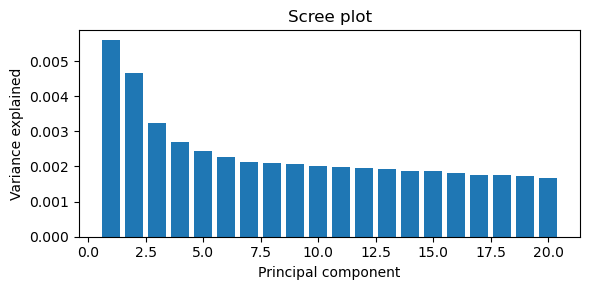

In [154]:
#Step 3: Interpret the principle components
# --- 3a. Top loading terms per PC ---
loadings = pd.DataFrame(
    pca.components_.T,
    index=matrix.idx2doc,       # fashion terms
    columns=[f'PC{i+1}' for i in range(n_components)]
)

def top_terms(pc, n=10):
    s = loadings[pc].sort_values(ascending=False)
    return s.head(n)

def bot_terms(pc, n=10):
    s = loadings[pc].sort_values(ascending=True)
    return s.head(n)

for i in range(1, 11):
    c = f"PC{i}"
    print(f"Top terms on {c}:")
    print(top_terms(c, 5))
    print(bot_terms(c, 5))

# --- 3b. Correlate PC scores with gender ---
# Map each char_adj back to its character's gender
# char_adj_gender: dict mapping char_adj → gender (1=male, 0=female)
from scipy.stats import pointbiserialr

# gender_labels = np.array([char_adj_gender[adj] for adj in matrix.idx2doc])

# for i in range(n_components):
#     r, p = pointbiserialr(gender_labels, coords[:, i])
#     print(f"PC{i+1}: r={r:.3f}, p={p:.4f}")

# --- 3c. Scree plot ---
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 3))
plt.bar(range(1, n_components+1), pca.explained_variance_ratio_)
plt.xlabel('Principal component')
plt.ylabel('Variance explained')
plt.title('Scree plot')
plt.tight_layout()
plt.savefig('scree.png', dpi=150)

In [95]:
import umap
import umap.plot


In [187]:
def umap_plot():
    um = umap.UMAP(metric="cosine").fit(coords[(~genders.gender_dep_pron.isna()).tolist()])
    return um

um = umap_plot()

In [120]:
pca.components_.shape

(10, 60136)

In [121]:
umap.plot.output_notebook()

Loading BokehJS ...

In [130]:
genders[genders.gender_dep_pron.isin(["male", "female"])].gender_dep_pron.index

unique_char_id
chi.086523141.clean-14              male
chi.086834615.clean-1694            male
coo.31924013205327.clean-201        male
coo.31924013205327.clean-194        male
coo.31924013205327.clean-489      female
                                   ...  
yale.39002003711067.clean-948       male
yale.39002003711067.clean-4404      male
yale.39002009910416.clean-5288      male
yale.39002009910416.clean-505       male
yale.39002013119517.clean-4866    female
Name: gender_dep_pron, Length: 17088, dtype: object

In [188]:

p = umap.plot.interactive(um, hover_data=pd.DataFrame({"gender": genders[~genders.gender_dep_pron.isna()].gender_dep_pron.tolist()}), labels=genders[~genders.gender_dep_pron.isna()].gender_dep_pron.tolist(), point_size=2)
umap.plot.show(p)

In [131]:
from scipy.stats import kendalltau

In [189]:
def _():
    mf = genders[genders.gender_dep_pron.isin(["male", "female"])].gender_dep_pron.apply(lambda x: {"male": 0, "female": 1}[x])
    pca_mf = coords[genders.gender_dep_pron.isin(["male", "female"])]

    for ax in range(pca_mf.shape[1]):
        print(f"Axis {ax}")
        print(kendalltau(pca_mf[:, ax], mf))

_()

Axis 0
SignificanceResult(statistic=np.float64(1.0785212331736875e-05), pvalue=np.float64(0.9986223644299017))
Axis 1
SignificanceResult(statistic=np.float64(0.37869679090498964), pvalue=np.float64(0.0))
Axis 2
SignificanceResult(statistic=np.float64(0.05846433202708504), pvalue=np.float64(8.004719699876523e-21))
Axis 3
SignificanceResult(statistic=np.float64(-0.05117682562756585), pvalue=np.float64(2.5494637132355994e-16))
Axis 4
SignificanceResult(statistic=np.float64(0.1356980518877018), pvalue=np.float64(1.2175705379214863e-104))
Axis 5
SignificanceResult(statistic=np.float64(-0.08680131548595867), pvalue=np.float64(6.691250601649361e-44))
Axis 6
SignificanceResult(statistic=np.float64(0.10097145578376295), pvalue=np.float64(8.964704442362975e-59))
Axis 7
SignificanceResult(statistic=np.float64(0.00020311156777963406), pvalue=np.float64(0.9740603568530577))
Axis 8
SignificanceResult(statistic=np.float64(0.03049986543245033), pvalue=np.float64(1.0462102830705855e-06))
Axis 9
Signifi

In [ ]:
years = merged_no_dupe.groupby("unique_char_id").inferreddate.head()

In [213]:
def _():
    # toggle: filter only by gender for apples-to-apples with the gender corr
    filter_gender = False
    years_dict = merged_no_dupe.groupby("unique_char_id").inferreddate.first().to_dict()
    if filter_gender:
        years = [years_dict[char] for char in np.array(matrix.idx2doc)[genders.gender_dep_pron.isin(["male", "female"])]]
        pca_coords = coords[genders.gender_dep_pron.isin(["male", "female"])]
    else:
        years = [years_dict[char] for char in matrix.idx2doc]
        pca_coords = coords
    for ax in range(pca_coords.shape[1]):
        print(f"Axis {ax}")
        print(kendalltau(pca_coords[:, ax], years))

_()

Axis 0
SignificanceResult(statistic=np.float64(0.05067388272869411), pvalue=np.float64(2.3033214018169633e-76))
Axis 1
SignificanceResult(statistic=np.float64(-0.13748434188847078), pvalue=np.float64(0.0))
Axis 2
SignificanceResult(statistic=np.float64(-0.038939548743082204), pvalue=np.float64(7.773704901976047e-46))
Axis 3
SignificanceResult(statistic=np.float64(-0.04833704484040126), pvalue=np.float64(1.1881304634537366e-69))
Axis 4
SignificanceResult(statistic=np.float64(0.008997124681192506), pvalue=np.float64(0.0010248301769411354))
Axis 5
SignificanceResult(statistic=np.float64(-0.053610415871371435), pvalue=np.float64(3.024260635331331e-85))
Axis 6
SignificanceResult(statistic=np.float64(0.06740487178938648), pvalue=np.float64(1.2538227009881793e-133))
Axis 7
SignificanceResult(statistic=np.float64(-0.006858530227740497), pvalue=np.float64(0.012310673372681146))
Axis 8
SignificanceResult(statistic=np.float64(-0.004814547448548932), pvalue=np.float64(0.0788951528292552))
Axis 9
S

In [198]:
merged_no_dupe.head()

mention_id      term  \
book_id             character_id                         
chi.086202240.clean 0               17370773    shorts   
                    218             17370789  covering   
                    218             17370790   topcoat   
                    0               17370796     shirt   
                    0               17370798     shirt   

                                                                           sentence  \
book_id             character_id                                                      
chi.086202240.clean 0             How long I remained in shorts I cannot novembe...   
                    218           Instantly I knew \nthat in order to assuage hi...   
                    218           Instantly I knew \nthat in order to assuage hi...   
                    0             Knowing in my own mind that \nmy shirt which I...   
                    0             Knowing in my own mind that \nmy shirt which I...   

                                  start_idx  end_idx  sentence_start_idx  \
book_id             character_id                                           
chi.086202240.clean 0                    23       29                4200   
                    218                 318      326               20869   
                    218                 334      341               20869   
                    0                    32       37               29540   
                    0                   277      282               29540   

                                  sentence_end_idx adjectives_fashion  \
book_id             character_id                                        
chi.086202240.clean 0                         4409                 []   
                    218                      21292             [thin]   
                    218                      21292                 []   
                    0                        29900                 []   
                    0                        29900                 []   

                                  character_start_idx  character_end_idx  \
book_id             character_id                                           
chi.086202240.clean 0                          4230.0             4231.0   
                    218                       21199.0            21202.0   
                    218                       21199.0            21202.0   
                    0                         29569.0            29571.0   
                    0                         29814.0            29816.0   

                                 gender_local_pron  \
book_id             character_id                     
chi.086202240.clean 0                         None   
                    218                       male   
                    218                       male   
                    0                         None   
                    0                         None   

                                                                        all_genders  \
book_id             character_id                                                      
chi.086202240.clean 0                                                          None   
                    218           {'female': None, 'male': ['his', 'he'], 'nonbi...   
                    218           {'female': None, 'male': ['his', 'he'], 'nonbi...   
                    0                                                          None   
                    0                                                          None   

                                 gender_dep_pron  \
book_id             character_id                   
chi.086202240.clean 0                       None   
                    218                     None   
                    218                     male   
                    0                       None   
                    0                       None   

                                                                    adjectives_char  

In [192]:
pca.components_.shape

(20, 928)

In [217]:
fashion_counts = merged_no_dupe.term.value_counts().to_dict()

In [384]:
merged_no_dupe.columns

Index(['mention_id', 'term', 'sentence', 'start_idx', 'end_idx',
       'sentence_start_idx', 'sentence_end_idx', 'adjectives_fashion',
       'character_start_idx', 'character_end_idx', 'gender_local_pron',
       'all_genders', 'gender_dep_pron', 'adjectives_char', 'gender_booknlp',
       'inferreddate', 'decade', 'decade_clean', 'term_stem',
       'unique_char_id'],
      dtype='object')

In [394]:
hathi_meta.loc["coo.31924014271260.clean"]

docid                                             coo.31924014271260
oldauthor                                        Sienkiewicz, Henryk
author                                           Sienkiewicz, Henryk
authordate                                                1846-1916.
inferreddate                                                  1914.0
latestcomp                                                    1914.0
datetype                                                           s
startdate                                                       1914
enddate                                                             
imprint                London;J. M. Dent;New York;E. P. Dutton;1914?
imprintdate                                                     1914
contents                                                         NaN
genres                                                           NaN
subjects           Translations from Polish|Polish fiction|Greek ...
geographics                       

In [388]:
merged_no_dupe[merged_no_dupe.term.eq("toga")].index.unique()

MultiIndex([( 'coo.31924013240779.clean',   575),
            ( 'coo.31924013543735.clean',   862),
            ( 'coo.31924013543735.clean',  1143),
            ( 'coo.31924013619998.clean',     0),
            ( 'coo.31924013619998.clean',  1469),
            ( 'coo.31924014271260.clean',   336),
            ( 'coo.31924014271260.clean',   340),
            ( 'coo.31924014271260.clean',   481),
            ( 'coo.31924014271260.clean',  1801),
            ( 'coo.31924014271260.clean',   403),
            ...
            (     'wu.89099756470.clean',   212),
            (     'wu.89099758971.clean',   616),
            (     'wu.89099773699.clean',   400),
            (     'wu.89099780850.clean',  1937),
            (     'wu.89099780850.clean',  2307),
            (     'wu.89099786253.clean',  2945),
            (     'wu.89104493606.clean',   225),
            ('yale.39002013119517.clean',  4468),
            ('yale.39002013119517.clean',  4294),
            ('yale.39002030972518.

In [226]:
def _():
    for comp in range(20):
        print(f"---Axis {comp}---")
        filtered = [str(word) for word in np.array(matrix.idx2word)[pca.components_[comp].argsort()] if fashion_counts[word] > 1000]
        print(filtered[-20:])
        print(filtered[:20])
        print("---")
_()

---Axis 0---
['frock', 'skirt', 'collar', 'gloves', 'lace', 'shirt', 'cloak', 'suit', 'hands', 'boots', 'hand', 'cap', 'shoes', 'pocket', 'silk', 'gown', 'coat', 'clothes', 'dress', 'hat']
['girdles', 'kirtle', 'turbans', 'tunics', 'shift', 'toga', 'coif', 'kilt', 'kerchiefs', 'headpiece', 'thong', 'scarfs', 'periwig', 'vests', 'holsters', 'regimentals', 'mantles', 'hoods', 'stole', 'pinafores']
---
---Axis 1---
['attire', 'hands', 'gloves', 'mantle', 'skirts', 'apron', 'costume', 'folds', 'velvet', 'robe', 'skirt', 'cloak', 'veil', 'shawl', 'dresses', 'gown', 'lace', 'bonnet', 'silk', 'dress']
['coat', 'hat', 'clothes', 'pocket', 'boots', 'shirt', 'trousers', 'suit', 'pockets', 'collar', 'overcoat', 'cap', 'waistcoat', 'pipe', 'leather', 'shoes', 'uniform', 'breeches', 'tie', 'bag']
---
---Axis 2---
['chaps', 'black', 'wraps', 'millinery', 'shawl', 'folds', 'wrap', 'band', 'muff', 'habit', 'beaver', 'glove', 'gown', 'hand', 'hats', 'veil', 'lace', 'dress', 'gloves', 'hat']
['clothes',

In [283]:
hathi_meta = pd.read_csv("../data/hathimeta/titlemeta.tsv", sep="\t")
hathi_meta.index = (hathi_meta.docid + ".clean").rename("book_id")
hathi_meta = hathi_meta[hathi_meta.index.isin(merged_no_dupe.index.get_level_values(0))]

/tmp/ipykernel_584899/1601542222.py:1: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  hathi_meta = pd.read_csv("../data/hathimeta/titlemeta.tsv", sep="\t")


In [373]:
import seaborn.objects as so
from scipy.spatial.distance import pdist
rng = np.random.default_rng(42)

In [369]:
hathi_meta.loc["nyp.33433074942669.clean"].title

'Afloat and ashore; or, The adventures of Miles Wallingford. | $c: By the author of "The two admirals", "Pilot" [etc.] ...'

In [367]:
genre_texts

{'Adventure fiction': ['nyp.33433074942669.clean',
  'nyp.33433003303751.clean',
  'mdp.39015054073138.clean',
  'nyp.33433074940861.clean',
  'nyp.33433074940861.clean',
  'nyp.33433074940861.clean',
  'mdp.39015031242194.clean',
  'nyp.33433074890454.clean',
  'uc1.32106005865453.clean',
  'mdp.39015060797969.clean',
  'nyp.33433075753065.clean',
  'njp.32101079836423.clean',
  'mdp.39015074363857.clean',
  'nyp.33433074878392.clean',
  'nyp.33433074807680.clean',
  'coo.31924111705111.clean',
  'uc1.b4512667.clean',
  'nyp.33433074864939.clean',
  'mdp.39015014499928.clean',
  'uc1.b4373265.clean',
  'njp.32101064214065.clean',
  'nyp.33433074848650.clean',
  'uva.x030788089.clean',
  'nyp.33433076089998.clean',
  'mdp.39015080461034.clean',
  'uc1.b3862333.clean',
  'njp.32101038061022.clean'],
 'Autobiographical fiction': ['nyp.33433074942669.clean',
  'njp.32101058459064.clean',
  'mdp.39015030449949.clean',
  'wu.89046693198.clean',
  'uc1.b3579144.clean',
  'nyp.33433074846654.

In [378]:
def mean_pairwise_1d(v):
    """Mean |vi - vj| over all pairs, O(n log n) via sorting."""
    v = np.sort(v)
    n = len(v)
    if n < 2:
        return np.nan
    k = np.arange(n)
    return ((2 * k - n + 1) @ v) / (n * (n - 1) / 2)

def genre_permutation_test(x, labels, n_perm=10_000, seed=0):
    x = np.asarray(x, dtype=float)
    labels = np.asarray(labels)
    genres, sizes = np.unique(labels, return_counts=True)

    def stats(lab):
        return np.array([mean_pairwise_1d(x[lab == g]) for g in genres])

    observed = stats(labels)

    rng = np.random.default_rng(seed)
    null = np.empty((n_perm, len(genres)))
    for i in range(n_perm):
        null[i] = stats(rng.permutation(labels))

    # one-sided: is the genre *tighter* than chance?
    p = ((null <= observed).sum(axis=0) + 1) / (n_perm + 1)
    p[np.isnan(observed)] = np.nan

    # omnibus: mean within-genre distance across all genres
    obs_all = np.nanmean(observed)
    null_all = np.nanmean(null, axis=1)
    p_all = ((null_all <= obs_all).sum() + 1) / (n_perm + 1)

    table = pd.DataFrame({
        "n": sizes,
        "observed": observed,
        "null_mean": null.mean(axis=0),
        "ratio": observed / null.mean(axis=0),
        "p_value": p,
    }, index=genres).sort_values("ratio")

    return table, p_all



In [382]:
# for each genre, find the texts that belong to it
genre_map = pd.read_csv("../data/hathi_genre_merges.csv", names=["original", "clean"], index_col=0).clean.to_dict()
genre_texts = hathi_meta.genres.dropna().str.split("|").explode().apply(genre_map.get).reset_index().groupby("genres").agg(list).to_dict()["book_id"]
# filter for only kinds of "fiction"
genre_texts = {k: v for k, v in genre_texts.items() if "fiction" in k.lower()}

def within_genre_distances(x, labels):
    """Mean pairwise distance among items within each genre."""
    df = pd.DataFrame({"x": x, "genre": labels})
    result = {}
    for genre, group in df.groupby("genre"):
        vals = group["x"].to_numpy().reshape(-1, 1)
        result[genre] = pdist(vals).mean() if len(vals) > 1 else np.nan
    return pd.Series(result, name="mean_within_dist").sort_values()
    
def calc_for_pc(pc):
    # for each text, calculate its position along the PC by averaging its character positions
    texts_with_genre = set(itertools.chain(*genre_texts.values()))

    text_positions = {}
    for text in texts_with_genre:
        text_characters = merged_no_dupe.loc[text, :].unique_char_id.unique()
        characters = [matrix.doc2idx[char] for char in text_characters if char in matrix.doc2idx]
        if len(characters) == 0:
            continue
        text_character_pc = coords[characters, pc].mean()
        text_positions[text] = text_character_pc
    
    # calculate the silhouette score for the genre assignments
    x, label, titles = [], [], []
    for genre, texts in genre_texts.items():
        for text in texts:
            if text in text_positions:
                x.append(text_positions[text])
                label.append(genre)
                titles.append(hathi_meta.loc[text].title.split("|")[0])
    # calculate the silhouette score for the genre assignments   
    # print(silhouette_score(np.array(x).reshape(-1, 1), label))
    # print(within_genre_distances(x, label).mean())
    # baseline = pdist(np.array(x).reshape(-1, 1)).mean()
    # print((within_genre_distances(x, label) / baseline).mean())

    table, p_all = genre_permutation_test(x, label)
    print(table)
    print(f"Total p = {p_all:.4f}")

    # sns.stripplot(x=x, hue=label, legend=False)
    # df = pd.DataFrame({"pos": x, "genre": label, "title": titles})
    # df["y"] = rng.uniform(-5, 5, len(df))

    # (
    #     so.Plot(df, x="pos", y="y", color="genre", text="title")
    #     .add(so.Dots(), legend=False)
    #     .add(so.Text(fontsize=7, valign="bottom", offset=6), legend=False)
    #     .layout(size=(14, 6))
    #     .show()
    # )
    # plt.show()

for i in range(20):
    print(i)
    calc_for_pc(i)
    # break # run permutation test by shuffling genre assignments


0
                                n  observed  null_mean     ratio   p_value
Romantic suspense fiction       3  0.295116   2.084446  0.141580  0.025797
Epic fiction                    2  0.296950   2.061576  0.144040  0.113689
Biographical fiction            4  0.458796   2.069311  0.221714  0.019798
Pastoral fiction                4  1.165094   2.064075  0.564463  0.230977
Science fiction                 7  1.288514   2.052297  0.627840  0.190481
Christmas fiction               3  1.421694   2.088455  0.680740  0.391761
Historical fiction             38  1.539178   2.051726  0.750187  0.068193
English fiction                 5  1.629435   2.056154  0.792467  0.430057
Western fiction                21  1.695521   2.061857  0.822327  0.256174
Political fiction              11  1.712938   2.060756  0.831219  0.379662
Christian fiction               3  1.824459   2.050547  0.889742  0.557244
Picaresque fiction              3  1.853534   2.042839  0.907332  0.571243
Mystery and detective f

In [294]:
texts_with_genre = set(itertools.chain(*genre_texts.values()))

In [303]:
text_characters = merged_no_dupe.loc["nyp.33433082525555.clean", :].unique_char_id.unique()

In [304]:
text_characters

array(['nyp.33433082525555.clean-0', 'nyp.33433082525555.clean-353',
       'nyp.33433082525555.clean-3882', 'nyp.33433082525555.clean-461',
       'nyp.33433082525555.clean-385', 'nyp.33433082525555.clean-209',
       'nyp.33433082525555.clean-208', 'nyp.33433082525555.clean-250',
       'nyp.33433082525555.clean-235', 'nyp.33433082525555.clean-559',
       'nyp.33433082525555.clean-400', 'nyp.33433082525555.clean-253',
       'nyp.33433082525555.clean-282', 'nyp.33433082525555.clean-3403',
       'nyp.33433082525555.clean-3452', 'nyp.33433082525555.clean-4128',
       'nyp.33433082525555.clean-298', 'nyp.33433082525555.clean-3633',
       'nyp.33433082525555.clean-3719'], dtype=object)

In [305]:
coords.shape

(60136, 20)

In [311]:
text_character_pc = coords[[matrix.doc2idx[char] for char in text_characters if char in matrix.doc2idx], 0].mean()

In [312]:
text_character_pc

np.float64(3.557651598550197)

In [339]:
len(texts_with_genre)

4108